# 04-2. 결빙 분류: 고전 ML 기법 비교

04(결빙 발생 분류)의 2장. 04-1의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블을 같은 조건(결빙관련 라벨, 같은 변수,
지점 단위 7묶음 교차검증, 일별 F1이 가장 높은 임계값)으로 비교한다. 최종 후보에 넣지 않는 참고용 비교이다.

04 구성: 04-1 Ice 라벨·후보 모델·교차검증(0~1장) · **04-2 고전 ML 비교(2장)** · 04-3 검증 지점 평가·저장(3~5장)

- 입력: 02-2의 지점 변수, 03-3의 추정 노면온도, 04-1의 교차검증 확률·설정 (`icing_oof.parquet`, `icing_cv.json`)
- 출력: 비교 결과 표 (`data/results/icing_model_comparison.csv`, `icing_mlp_architectures.csv`, `icing_ensembles.csv`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [ ]:
import itertools
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from cycler import cycler
from joblib import Parallel, delayed
from matplotlib import font_manager
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [ ]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점 (04-1과 같음)
sf["date"] = sf["time"].dt.normalize()
cv = json.load(open(config.PROCESSED_DIR / "icing_cv.json", encoding="utf-8"))  # 04-1에서 정한 설정
CLS_FEATURES, folds, FINAL, INTERPRET = cv["features"], cv["folds"], cv["final"], cv["interpret"]
sf["related"] = sf["state"].isin(cv["related_states"]).astype("float32").where(sf["state"].notna())
train_all = sf[~sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
stns = sorted(train_all["stn"].unique())

# 04-1의 학습 지점 교차검증 확률 (후보 3개)
oof_prob = pd.read_parquet(config.PROCESSED_DIR / "icing_oof.parquet")
assert oof_prob["stn"].equals(train_all["stn"]) and oof_prob["time"].equals(train_all["time"])
oof_prob = oof_prob.drop(columns=["stn", "time"])
print(f"학습 지점 {len(stns)}곳, 최종 모델: {FINAL}, 해석용 모델: {INTERPRET}")

## 2. 고전 ML 기법 비교

"LightGBM이 최선인가"를 확인하려고 다른 고전 머신러닝 기법도 **같은 조건**(결빙관련 라벨, 같은 26개 변수, 양성 가중치 5,
지점 단위 7묶음 교차검증, 일별 F1이 가장 높은 임계값)으로 비교한다. 이 절의 기법들은 최종 후보에 넣지 않는 참고용 비교이다.

| 기법 | 설정 |
|------|------|
| XGBoost | 깊이 4, 400회, 학습률 0.03 (LightGBM과 같은 부스팅 계열) |
| 스플라인 로지스틱 (GAM 근사) | 변수별 3차 스플라인(매듭 5개)을 만든 뒤 로지스틱 (C=0.05). 변수마다 비선형 효과를 허용 |
| Random Forest | 200그루, 잎 최소 50행, 그루마다 30% 표본 |
| Extra Trees | 200그루, 잎 최소 50행, 무작위 분할 |
| MLP | 은닉층 32-16 (ReLU), L2 1e-3, 조기 종료. 표준화 입력 |

In [12]:
POS_W = 5


def imputed(*steps):
    return make_pipeline(SimpleImputer(strategy="median"), *steps)


OTHER_MODELS = {
    "XGBoost": lambda: xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4, min_child_weight=50,
                                         subsample=0.7, colsample_bytree=0.7, reg_lambda=5.0, scale_pos_weight=POS_W,
                                         tree_method="hist", n_jobs=4, random_state=SEED),
    "스플라인 로지스틱(GAM)": lambda: imputed(SplineTransformer(n_knots=5, extrapolation="linear"), StandardScaler(),
                                      LogisticRegression(C=0.05, class_weight={0: 1, 1: POS_W}, max_iter=3000)),
    "Random Forest": lambda: imputed(RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features="sqrt",
                                                            max_samples=0.3, class_weight={0: 1, 1: POS_W},
                                                            n_jobs=-1, random_state=SEED)),
    "Extra Trees": lambda: imputed(ExtraTreesClassifier(n_estimators=200, min_samples_leaf=50, max_features=0.5,
                                                        max_samples=0.3, bootstrap=True, class_weight={0: 1, 1: POS_W},
                                                        n_jobs=-1, random_state=SEED)),
    "MLP(32-16)": lambda: imputed(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3,
                                                                  early_stopping=True, max_iter=80, batch_size=512,
                                                                  random_state=SEED)),
}


def fit_related(make, df):
    """결빙관련 라벨로 학습한다. MLP는 class_weight가 없어 양성 표본 가중치로 같은 효과를 준다."""
    d = df.dropna(subset=["related"])
    y = d["related"].astype(int)
    m = make()
    if hasattr(m, "steps") and isinstance(m[-1], MLPClassifier):
        return m.fit(d[CLS_FEATURES], y, mlpclassifier__sample_weight=np.where(y == 1, POS_W, 1.0))
    return m.fit(d[CLS_FEATURES], y)


def oof_related(make):
    prob = np.full(len(train_all), np.nan)
    for val_stns in folds:
        va = train_all["stn"].isin(val_stns).to_numpy()
        prob[va] = fit_related(make, train_all[~va]).predict_proba(train_all.loc[va, CLS_FEATURES])[:, 1]
    return prob


cmp_prob = pd.DataFrame({"LightGBM(결빙관련 라벨)": oof_prob["LightGBM(결빙관련 라벨)"],
                         "로지스틱 회귀(결빙관련 라벨)": oof_prob["로지스틱 회귀(결빙관련 라벨)"]})
cmp_time = {}
for name, make in OTHER_MODELS.items():
    t0 = time.time()
    cmp_prob[name] = oof_related(make)
    cmp_time[name] = time.time() - t0
    print(f"{name}: {cmp_time[name]:.0f}s")

XGBoost: 31s


스플라인 로지스틱(GAM): 110s


Random Forest: 108s


Extra Trees: 63s


MLP(32-16): 134s


모델 간 일별 F1 차이가 우연인지 보려고 **날짜 단위 부트스트랩**(1,000회)으로 차이의 95% 구간을 구한다.
같은 날의 여러 지점은 같은 기상을 겪으므로 날짜를 통째로 다시 뽑는다. 계산을 빠르게 하려고 일별 F1을 지점-날 단위 배열로 미리 만든다.

In [13]:
lab_rows = train_all["ice"].notna().to_numpy()
stn_pos = {s: i for i, s in enumerate(stns)}
day_key, _ = pd.factorize(train_all.loc[lab_rows, "stn"].astype(str) + "_"
                          + train_all.loc[lab_rows, "time"].dt.strftime("%Y%m%d"))
day_stn = np.zeros(day_key.max() + 1, int)
day_stn[day_key] = train_all.loc[lab_rows, "stn"].map(stn_pos).to_numpy()
day_date = np.zeros(day_key.max() + 1, int)
day_date[day_key] = pd.factorize(train_all.loc[lab_rows, "time"].dt.normalize())[0]
y_lab = train_all.loc[lab_rows, "ice"].astype(int).to_numpy()


def day_f1(pred):
    """지점-날별 (F1, 평가 여부). 평가 = 그날 실제·예측 결빙이 하나라도 있음 (빈 날 제외 방식)."""
    p = np.asarray(pred)[lab_rows].astype(int)
    tp = np.bincount(day_key, y_lab & p)
    fp = np.bincount(day_key, (1 - y_lab) & p)
    fn = np.bincount(day_key, y_lab & (1 - p))
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0), den > 0


def mean_daily_f1(f1, ev, station_idx=None, date_w=None):
    """지점별 평가일 평균 → 지점 평균 (daily_f1과 같은 값). date_w: 날짜별 부트스트랩 가중치."""
    w = ev * (1.0 if date_w is None else date_w[day_date])
    s_sum = np.bincount(day_stn, f1 * w, len(stns))
    s_n = np.bincount(day_stn, w, len(stns))
    per = np.where(s_n > 0, s_sum / np.where(s_n > 0, s_n, 1), np.nan)
    return np.nanmean(per if station_idx is None else per[station_idx])


def best_thr_fast(score_vec, station_idx=None):
    cands = np.unique(np.quantile(score_vec[~np.isnan(score_vec)], (0.95, 0.98, 0.99, 0.995, 0.998, 0.999, 0.9995, 0.9998)))
    vals = [mean_daily_f1(*day_f1(score_vec >= t), station_idx) for t in cands]
    return cands[int(np.argmax(vals))], max(vals)


related_ok = train_all["related"].notna().to_numpy()
rows = []
day_scores = {}
for name in cmp_prob:
    prob = cmp_prob[name].to_numpy()
    thr, f1 = best_thr_fast(prob)
    day_scores[name] = day_f1(prob >= thr)
    rows.append({"방법": name, "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                 "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                 "일별 F1 (빈 날 제외)": f1, "Ice 포착률(10분)": (prob >= thr)[lab_rows][y_lab == 1].mean(),
                 "결빙 판정 비율": (prob >= thr).mean(), "학습 시간(s)": cmp_time.get(name, np.nan)})
cmp_table = pd.DataFrame(rows).set_index("방법")

n_dates = day_date.max() + 1
rng = np.random.default_rng(SEED)
boot_w = np.stack([np.bincount(rng.integers(0, n_dates, n_dates), minlength=n_dates) for _ in range(1000)])
ref = FINAL if FINAL in cmp_prob else "LightGBM(결빙관련 라벨)"
ref_boot = np.array([mean_daily_f1(*day_scores[ref], date_w=w) for w in boot_w])
for name in cmp_prob:
    diff = np.array([mean_daily_f1(*day_scores[name], date_w=w) for w in boot_w]) - ref_boot
    cmp_table.loc[name, f"{ref} 대비 차이"] = cmp_table.loc[name, "일별 F1 (빈 날 제외)"] - cmp_table.loc[ref, "일별 F1 (빈 날 제외)"]
    cmp_table.loc[name, "95% 구간"] = f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]"
print("참고: Ice 비율(무작위 예측의 AP) =", round(y_lab.mean(), 5))
cmp_table.sort_values("일별 F1 (빈 날 제외)", ascending=False).round(4)

참고: Ice 비율(무작위 예측의 AP) = 0.0005


,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),Ice 포착률(10분),결빙 판정 비율,학습 시간(s),LightGBM(결빙관련 라벨) 대비 차이,95% 구간
방법,,,,,,,,
로지스틱 회귀(결빙관련 라벨),0.0089,0.4858,0.0301,0.2385,0.010,NaN,0.0045,"[-0.0101, +0.0228]"
LightGBM(결빙관련 라벨),0.0098,0.4701,0.0256,0.1506,0.005,NaN,0.0000,"[+0.0000, +0.0000]"
XGBoost,0.0108,0.4920,0.0244,0.2720,0.010,30.8773,-0.0012,"[-0.0128, +0.0089]"
스플라인 로지스틱(GAM),0.0106,0.4555,0.0237,0.1548,0.005,110.0029,-0.0019,"[-0.0134, +0.0134]"
Random Forest,0.0091,0.4999,0.0225,0.2385,0.010,107.9146,-0.0031,"[-0.0203, +0.0100]"
Extra Trees,0.0087,0.5060,0.0209,0.2301,0.010,63.2780,-0.0048,"[-0.0174, +0.0070]"
MLP(32-16),0.0098,0.4562,0.0163,0.4686,0.020,133.9208,-0.0094,"[-0.0263, +0.0045]"


- 7개 기법의 일별 F1은 0.016~0.030, AP(Ice)는 0.0087~0.0108로 모두 비슷하다 (무작위 예측 AP 0.0005의 약 20배).
- 최종 모델(LightGBM) 대비 차이의 95% 구간이 모두 0을 포함한다.
  예: 로지스틱 +0.005 [-0.010, +0.023], XGBoost -0.001 [-0.013, +0.009], Random Forest -0.003 [-0.020, +0.010],
  MLP -0.009 [-0.026, +0.005]. **어느 기법이 낫다고 말할 수 없다.**
- 지표마다 1위도 다르다. 일별 F1은 로지스틱, AP(Ice)는 XGBoost·스플라인 로지스틱, AP(결빙관련)는 Extra Trees·Random Forest가 가장 높다.
- 성능을 정하는 것은 기법보다 라벨이다. 0절에서 본 것처럼 실제 노면상태를 알아도 일별 F1의 상한이 0.1에 못 미친다.

### 2-1. MLP 구조 실험

신경망은 층을 어떻게 쌓느냐에 따라 결과가 달라질 수 있으므로, 은닉층의 **너비**(16~256), **깊이**(1~4층), **L2 규제**, **활성화 함수**,
**여러 시드 평균**을 바꿔 가며 같은 교차검증으로 비교한다. 모두 표준화 입력, Adam, 미니배치 512, 학습 자료 10%로 조기 종료한다.

In [14]:
MLP_ARCHS = [
    ("1층 16", (16,), {}), ("1층 64", (64,), {}), ("1층 256", (256,), {}),
    ("2층 32-16", (32, 16), {}), ("2층 64-64", (64, 64), {}), ("2층 256-256", (256, 256), {}),
    ("3층 128-64-32", (128, 64, 32), {}), ("4층 256-128-64-32", (256, 128, 64, 32), {}),
    ("2층 32-16, L2 0.1", (32, 16), {"alpha": 0.1}), ("2층 32-16, L2 1", (32, 16), {"alpha": 1.0}),
    ("2층 32-16, tanh", (32, 16), {"activation": "tanh"}),
    ("2층 32-16, 시드 5개 평균", (32, 16), {"seeds": 5}),
]


def mlp_fold(data, hidden, opt, val_stns, seed):
    """한 묶음의 MLP 학습·예측 (7묶음 병렬, 묶음당 BLAS 2스레드). 반환: (검증 행 마스크, 확률)."""
    warnings.filterwarnings("ignore", category=UserWarning)
    with threadpool_limits(2):
        va = data["stn"].isin(val_stns).to_numpy()
        make = lambda: imputed(StandardScaler(), MLPClassifier(  # noqa: E731
            hidden_layer_sizes=hidden, alpha=opt.get("alpha", 1e-3), activation=opt.get("activation", "relu"),
            early_stopping=True, max_iter=80, batch_size=512, random_state=seed))
        return va, fit_related(make, data[~va]).predict_proba(data.loc[va, CLS_FEATURES])[:, 1]


mlp_rows, mlp_prob = [], {}
mlp_data = train_all[["stn", "related"] + CLS_FEATURES]
for name, hidden, opt in MLP_ARCHS:
    t0 = time.time()
    outs = Parallel(n_jobs=7)(delayed(mlp_fold)(mlp_data, hidden, opt, v, SEED + k)
                              for k in range(opt.get("seeds", 1)) for v in folds)
    acc, cnt = np.zeros(len(train_all)), np.zeros(len(train_all))
    for va, p in outs:
        acc[va] += p
        cnt[va] += 1
    prob = acc / np.maximum(cnt, 1)
    mlp_prob[name] = prob
    n_params = sum(a * b for a, b in zip((len(CLS_FEATURES),) + hidden, hidden + (1,))) + sum(hidden) + 1
    mlp_rows.append({"구조": name, "층 수": len(hidden), "매개변수 수": n_params,
                     "AP(Ice)": average_precision_score(y_lab, prob[lab_rows]),
                     "AP(결빙관련)": average_precision_score(train_all.loc[related_ok, "related"], prob[related_ok]),
                     "일별 F1 (빈 날 제외)": best_thr_fast(prob)[1], "학습 시간(s)": time.time() - t0})
    print(f"{name}: {time.time() - t0:.0f}s")
mlp_table = pd.DataFrame(mlp_rows).set_index("구조")
mlp_table.round(4)

1층 16: 22s


1층 64: 33s


1층 256: 98s


2층 32-16: 37s


2층 64-64: 62s


2층 256-256: 203s


... (3 outputs left out)

2층 32-16, L2 1: 14s


2층 32-16, tanh: 28s


2층 32-16, 시드 5개 평균: 132s


,층 수,매개변수 수,AP(Ice),AP(결빙관련),일별 F1 (빈 날 제외),학습 시간(s)
구조,,,,,,
1층 16,1,449,0.0090,0.4760,0.0177,22.0567
1층 64,1,1793,0.0097,0.4709,0.0208,33.4280
1층 256,1,7169,0.0101,0.4136,0.0192,97.9110
2층 32-16,2,1409,0.0098,0.4562,0.0163,36.9262
2층 64-64,2,5953,0.0091,0.4218,0.0203,62.0490
2층 256-256,2,72961,0.0075,0.3924,0.0185,202.7001
3층 128-64-32,3,13825,0.0070,0.3924,0.0139,71.0853
4층 256-128-64-32,4,50177,0.0098,0.3933,0.0180,171.8482
"2층 32-16, L2 0.1",2,1409,0.0094,0.4786,0.0191,31.0543


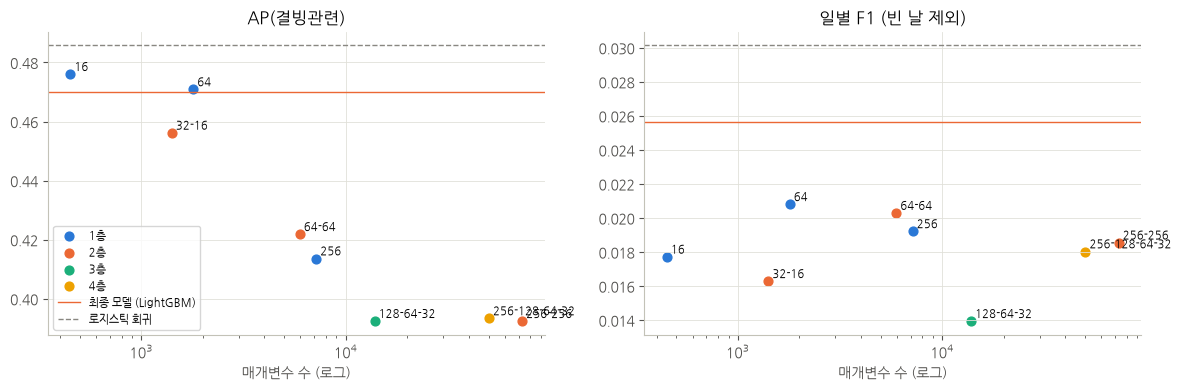

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plain = mlp_table[~mlp_table.index.str.contains(",")]
for ax, col in zip(axes, ["AP(결빙관련)", "일별 F1 (빈 날 제외)"]):
    for depth, g in plain.groupby("층 수"):
        ax.scatter(g["매개변수 수"], g[col], s=40, label=f"{depth}층")
        for name, r in g.iterrows():
            ax.annotate(name.split(" ")[1], (r["매개변수 수"], r[col]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axhline(cmp_table.loc[FINAL, col], color="#eb6834", linewidth=1, label="최종 모델 (LightGBM)")
    ax.axhline(cmp_table.loc[INTERPRET, col], color="#898781", linewidth=1, linestyle="--", label="로지스틱 회귀")
    ax.set_xscale("log")
    ax.set_xlabel("매개변수 수 (로그)")
    ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

- 노면온도 추정(03-2의 3-2)과 같은 양상이다. 크고 깊을수록 결빙관련 AP가 떨어진다.
  1층 16개 0.476 → 2층 256-256 0.392, 3층 128-64-32 0.392, 4층 256-128-64-32 0.393.
- 가장 좋은 구조는 강한 규제(L2 1)를 건 2층 32-16이다 (AP 0.496, 일별 F1 0.027). 시드 5개를 평균해도 0.456 → 0.490으로 나아진다.
  규제·평균처럼 **분산을 줄이는 쪽만 도움이 된다.**
- 그래도 LightGBM(AP 0.470, 일별 F1 0.026)·로지스틱 회귀(0.486, 0.030)와 같은 수준이다.
  학습 지점이 14곳뿐이라 신경망의 표현력이 이점이 되지 못한다.

### 2-2. 앙상블 실험

서로 다른 모델의 확률을 합치면 나아지는지 본다. 모델마다 확률의 크기가 다르므로 **순위 평균**(각 모델 확률을 0~1 백분위로 바꿔 평균)을 쓴다.
후보는 위 7개 모델(LightGBM, 로지스틱, XGBoost, 스플라인 로지스틱, RF, Extra Trees, MLP 32-16)의 2~4개 조합 전부이다.

같은 교차검증 결과로 조합을 고르면 고른 과정 자체가 점수를 부풀린다(선택 편향). 그래서 **중첩 교차검증**으로 정직한 점수도 함께 낸다:
7묶음마다 나머지 12개 지점만으로 조합과 임계값을 고르고, 그 묶음 지점에 적용한다.

In [16]:
ENS_POOL = list(cmp_prob.columns)
ranks = cmp_prob.rank(pct=True).to_numpy()
subsets = [c for k in range(1, 5) for c in itertools.combinations(range(len(ENS_POOL)), k)]
sub_score = {c: ranks[:, list(c)].mean(axis=1) for c in subsets}
sub_f1 = {c: best_thr_fast(v)[1] for c, v in sub_score.items()}
ens_top = pd.DataFrame([{"조합": " + ".join(ENS_POOL[i] for i in c), "모델 수": len(c), "일별 F1 (빈 날 제외)": f1,
                         "AP(Ice)": average_precision_score(y_lab, sub_score[c][lab_rows])}
                        for c, f1 in sorted(sub_f1.items(), key=lambda kv: -kv[1])[:10]])
print("조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적):",
      {k: round(max(v for c, v in sub_f1.items() if len(c) == k), 4) for k in range(1, 5)})
ens_top.round(4)

조합 크기별 최고 일별 F1 (같은 교차검증으로 고름, 낙관적): {1: np.float64(0.0301), 2: np.float64(0.0284), 3: np.float64(0.0352), 4: np.float64(0.0323)}


,조합,모델 수,일별 F1 (빈 날 제외),AP(Ice)
0,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,3,0.0352,0.0106
1,로지스틱 회귀(결빙관련 라벨) + 스플라인 로지스틱(GAM) + MLP(32-16),3,0.0344,0.0104
2,로지스틱 회귀(결빙관련 라벨) + XGBoost + 스플라인 로지스틱(GAM),3,0.0343,0.0108
3,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,4,0.0323,0.0105
4,로지스틱 회귀(결빙관련 라벨),1,0.0301,0.0089
5,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...,4,0.0300,0.0103
6,XGBoost + Random Forest + Extra Trees + MLP(32...,4,0.0299,0.0096
7,LightGBM(결빙관련 라벨) + Random Forest + Extra Tree...,4,0.0298,0.0097
8,LightGBM(결빙관련 라벨) + XGBoost + 스플라인 로지스틱(GAM),3,0.0297,0.0109
9,로지스틱 회귀(결빙관련 라벨) + Random Forest + MLP(32-16),3,0.0292,0.0099


In [17]:
def nested_daily_f1(candidates):
    """묶음마다 나머지 지점으로 조합·임계값을 고르고 묶음에 적용한 예측의 일별 F1."""
    pred, picks = np.zeros(len(train_all), bool), []
    for val_stns in folds:
        tr_idx = np.array([stn_pos[s] for s in stns if s not in val_stns])
        best = max(candidates, key=lambda c: best_thr_fast(sub_score[c], tr_idx)[1])
        thr, _ = best_thr_fast(sub_score[best], tr_idx)
        va = train_all["stn"].isin(val_stns).to_numpy()
        pred[va] = sub_score[best][va] >= thr
        picks.append(" + ".join(ENS_POOL[i] for i in best))
    return mean_daily_f1(*day_f1(pred)), pd.Series(picks).value_counts().to_dict()


def fixed(*names):
    return [tuple(sorted(ENS_POOL.index(n) for n in names))]


NESTED = {
    "LightGBM 고정 (최종 모델)": fixed("LightGBM(결빙관련 라벨)"),
    "로지스틱 고정": fixed("로지스틱 회귀(결빙관련 라벨)"),
    "LightGBM + 로지스틱 순위 평균 고정": fixed("LightGBM(결빙관련 라벨)", "로지스틱 회귀(결빙관련 라벨)"),
    "7개 전체 순위 평균 고정": [tuple(range(len(ENS_POOL)))],
    "단일 모델 선택 (중첩)": [c for c in subsets if len(c) == 1],
    "조합 선택 2~4개 (중첩)": [c for c in subsets if len(c) >= 2],
}
for c in NESTED["7개 전체 순위 평균 고정"]:
    sub_score[c] = ranks.mean(axis=1)
nested_rows = []
for name, cand in NESTED.items():
    f1, picks = nested_daily_f1(cand)
    nested_rows.append({"방법": name, "일별 F1 (빈 날 제외, 정직)": f1,
                        "묶음별 선택": "; ".join(f"{k} ({v}회)" for k, v in picks.items()) if len(cand) > 1 else ""})
pd.DataFrame(nested_rows).set_index("방법").round(4)

,"일별 F1 (빈 날 제외, 정직)",묶음별 선택
방법,,
LightGBM 고정 (최종 모델),0.0256,
로지스틱 고정,0.0301,
LightGBM + 로지스틱 순위 평균 고정,0.0236,
7개 전체 순위 평균 고정,0.0143,
단일 모델 선택 (중첩),0.0206,로지스틱 회귀(결빙관련 라벨) (6회); XGBoost (1회)
조합 선택 2~4개 (중첩),0.0186,LightGBM(결빙관련 라벨) + 로지스틱 회귀(결빙관련 라벨) + 스플라인 로지...


- 같은 교차검증으로 고르면 3개 조합(LightGBM + 로지스틱 + 스플라인 로지스틱 등)이 0.035로 가장 높아 보인다.
  하지만 고르는 과정까지 중첩 교차검증으로 평가하면 0.019로, 단일 모델을 고르는 경우(0.021)보다도 낮다.
  묶음마다 고르는 조합이 바뀌고, 일별 F1이 몇 날의 결과에 크게 흔들리기 때문이다 (선택 편향).
- 고정 조합도 나아지지 않는다: LightGBM + 로지스틱 0.024, 7개 전체 0.014 (LightGBM 단독 0.026, 로지스틱 단독 0.030).
- "고정" 행은 임계값을 14개 지점 전체로 고른 것이라 중첩 행보다 조금 낙관적이다. 같은 조건에서 정직하게 단일 모델을 고른 점수는 0.021이다.
- **앙상블은 쓰지 않는다.**

### 2-3. 정리

| 실험 | 결과 | 판단 |
|------|------|------|
| 다른 고전 기법 7종 (2절) | 일별 F1 0.016~0.030, LightGBM과의 차이 95% 구간이 모두 0 포함 | LightGBM이 최선이라고 할 수 없다. 어느 기법도 뚜렷이 낫지 않다 |
| MLP 구조 12가지 (2-1) | 작고 규제가 강할수록 좋다 (최고 AP 0.496) | 신경망의 이점이 없다 |
| 앙상블 (2-2) | 중첩 정직 점수 0.019 (단일 모델 선택 0.021) | 쓰지 않는다 |

- **최종 모델은 LightGBM(결빙관련 라벨)이고, 로지스틱 회귀는 해석용으로 함께 제시한다** (선택 과정은 1절).
  두 모델의 성능은 교차검증으로 구분되지 않는다. LightGBM은 Ice AP와 검증 지점 성능이 조금 높고,
  로지스틱은 계수로 결빙 요인의 방향을 바로 읽을 수 있어 05의 위험도 해석과 연결하기 쉽다.
- 결빙 분류의 성능을 정하는 것은 기법이 아니라 **라벨**(10분 단위로 깜빡이는 Ice, 제빙제 영향 코드)과 **학습 지점 수**이다.

## 저장

- `data/results/icing_model_comparison.csv`, `icing_mlp_architectures.csv`, `icing_ensembles.csv`: 기법 비교·MLP 구조·앙상블 결과

In [ ]:
cmp_table.round(4).to_csv(config.RESULT_DIR / "icing_model_comparison.csv", encoding="utf-8-sig")
mlp_table.round(4).to_csv(config.RESULT_DIR / "icing_mlp_architectures.csv", encoding="utf-8-sig")
pd.DataFrame(nested_rows).round(4).to_csv(config.RESULT_DIR / "icing_ensembles.csv", index=False, encoding="utf-8-sig")
print("저장 완료")